# STLab03 – Unit Testing & Assertions (EduParking)
**Sinh viên:** 21110275_Mai Nguyễn Ngọc Duy &nbsp;&nbsp;|&nbsp; **GitHub:** https://github.com/gemD0603/STLab03-Unit-Testing-Assertions.git <user>/<repo>

Chạy lần lượt từ trên xuống (**Runtime ▸ Run all**) để notebook có đủ output trước khi nộp. Expected suy ra từ requirement, không sửa expected cho khớp ứng dụng. Không sửa `parking_app.py` trước khi có Test Report v1.

## Bước 1 — Chuẩn bị môi trường

In [1]:
%pip -q install pytest pytest-cov pytest-html openpyxl matplotlib pandas

import os, sys
from pathlib import Path

if Path.cwd().name != "stlab03_work":          # chạy lại cell này nhiều lần vẫn an toàn
    Path("stlab03_work").mkdir(exist_ok=True)
    os.chdir("stlab03_work")
sys.path.insert(0, os.getcwd())
os.environ["PYTHONDONTWRITEBYTECODE"] = "1"
print("Python", sys.version.split()[0])
print("Thư mục làm việc:", Path.cwd().name)

Python 3.13.18
Thư mục làm việc: stlab03_work


## Bước 2 — STEP 1: Requirement và ứng dụng EduParking v1
(Điểm chưa rõ của requirement được ghi trong báo cáo, mục Phần 3.)

In [2]:
REQUIREMENTS = {
    "REQ-01": "Biển số đúng dạng NNL-NNNNN (2 số, 1 chữ hoa, gạch nối, 5 số)",
    "REQ-02": "Giờ gửi làm tròn LÊN theo giờ, tối thiểu 1 giờ; đúng 60 phút tính 1 giờ; giờ ra trước giờ vào báo INVALID_TIME",
    "REQ-03": "MOTORBIKE: 5.000đ cho 4 giờ đầu, thêm 2.000đ/giờ, tối đa 30.000đ; số giờ < 1 báo INVALID_HOURS",
    "REQ-04": "CAR: 20.000đ cho 2 giờ đầu, thêm 10.000đ/giờ, tối đa 200.000đ; loại xe khác báo INVALID_VEHICLE (cả khi check-in)",
    "REQ-05": "Tỉ lệ lấp đầy = số xe / sức chứa x 100; sức chứa <= 0 báo INVALID_CAPACITY",
    "REQ-06": "Được vào khi: biển số hợp lệ, không trong danh sách đen, nợ DƯỚI 100.000đ; ngược lại check-in báo NOT_ALLOWED",
    "REQ-07": "Check-in thành công: ghi nhận xe, số xe trong bãi tăng 1",
    "REQ-08": "Bãi đầy báo LOT_FULL; dữ liệu không đổi",
    "REQ-09": "Xe đang ở trong bãi check-in lại báo ALREADY_INSIDE; số xe không đổi",
    "REQ-10": "Check-out: trả về phí, số xe giảm 1, xóa xe khỏi bãi, doanh thu CỘNG DỒN",
    "REQ-11": "Check-out xe không có trong bãi báo NOT_INSIDE",
    "REQ-12": "Mất vé: cộng phụ thu 50.000đ vào phí VÀ vào doanh thu",
}
print(len(REQUIREMENTS), "requirements")

12 requirements


In [3]:
%%writefile parking_app.py
"""EduParking v1: bãi giữ xe chạy trong bộ nhớ, dùng cho bài tập STLab03."""
import re
from datetime import datetime

# loại xe: (giá gói đầu, số giờ gói đầu, giá mỗi giờ thêm, mức trần)
PRICE = {"MOTORBIKE": (5_000, 4, 2_000, 30_000), "CAR": (20_000, 2, 10_000, 200_000)}
DEBT_LIMIT = 100_000
LOST_TICKET = 50_000


# ---------- PHẦN A: hàm thuần ----------
def is_valid_plate(plate):
    return bool(re.fullmatch(r"[0-9]{2}[A-Z]-[0-9]{5}", plate))


def parked_hours(time_in, time_out):
    if time_out < time_in:
        raise ValueError("INVALID_TIME")
    minutes = int((time_out - time_in).total_seconds() // 60)
    return minutes // 60 + 1


def parking_fee(vehicle, hours):
    if vehicle not in PRICE:
        raise ValueError("INVALID_VEHICLE")
    if hours < 1:
        raise ValueError("INVALID_HOURS")
    base, base_hours, extra, cap = PRICE[vehicle]
    fee = base + max(0, hours - base_hours) * extra
    return min(fee, cap)


def occupancy_rate(occupied, capacity):
    if capacity <= 0:
        raise ValueError("INVALID_CAPACITY")
    return occupied / capacity * 100


# ---------- PHẦN B: lớp có state ----------
class ParkingLot:
    def __init__(self, capacity):
        self.capacity = capacity
        self.occupied = 0
        self.inside = {}       # biển số -> (loại xe, giờ vào)
        self.debts = {}        # biển số -> số tiền nợ
        self.blacklist = set()
        self.revenue = 0

    def can_enter(self, plate):
        return (is_valid_plate(plate)
                and plate not in self.blacklist
                and self.debts.get(plate, 0) <= DEBT_LIMIT)

    def check_in(self, plate, vehicle, time_in):
        if not self.can_enter(plate):
            raise ValueError("NOT_ALLOWED")
        if vehicle not in PRICE:
            raise ValueError("INVALID_VEHICLE")
        if self.occupied >= self.capacity:
            raise ValueError("LOT_FULL")
        self.occupied += 1
        if plate in self.inside:
            raise ValueError("ALREADY_INSIDE")
        self.inside[plate] = (vehicle, time_in)

    def check_out(self, plate, time_out, lost_ticket=False):
        if plate not in self.inside:
            raise ValueError("NOT_INSIDE")
        vehicle, time_in = self.inside[plate]
        fee = parking_fee(vehicle, parked_hours(time_in, time_out))
        self.revenue += fee
        if lost_ticket:
            fee += LOST_TICKET
        del self.inside[plate]
        self.occupied -= 1
        return fee

Writing parking_app.py


In [4]:
from datetime import datetime
from parking_app import ParkingLot, parking_fee, parked_hours

lot = ParkingLot(2)
lot.check_in("59A-12345", "MOTORBIKE", datetime(2026, 3, 1, 8, 0))
print("Sau check-in :", lot.occupied, lot.inside)
print("Phí 3 giờ    :", lot.check_out("59A-12345", datetime(2026, 3, 1, 11, 0)))
print("Doanh thu    :", lot.revenue)
print("Phí MOTORBIKE 17 giờ:", parking_fee("MOTORBIKE", 17))

Sau check-in : 1 {'59A-12345': ('MOTORBIKE', datetime.datetime(2026, 3, 1, 8, 0))}
Phí 3 giờ    : 5000
Doanh thu    : 5000
Phí MOTORBIKE 17 giờ: 30000


## Bước 3 — STEP 2/3: Bảng test data và unit test (E02, E03, E04, E05, E06)
Bảng test data đầy đủ 12 REQ nằm trong báo cáo (mục 3). Code test bên dưới bám theo bảng đó.

In [5]:
%%writefile test_functions.py
"""Unit test cho PHẦN A (REQ-01 đến REQ-05): các hàm thuần của EduParking.

Expected được suy ra từ requirement (tính tay), KHÔNG chép lại công thức trong code.
"""
from datetime import datetime, timedelta

import pytest

from parking_app import is_valid_plate, occupancy_rate, parked_hours, parking_fee, ParkingLot

IN = datetime(2026, 3, 1, 8, 0)


class TestReq01Plate:
    def test_positive_standard_plate_is_valid(self):
        plate = "59A-12345"                       # Arrange
        result = is_valid_plate(plate)            # Act
        assert result is True                     # Assert (boolean)

    @pytest.mark.parametrize("plate", [
        "", "5A-12345", "59a-12345", "59A12345", "59A-1234", "59A-123456", "5AA-12345", "595-12345",
    ])
    def test_negative_wrong_format_is_invalid(self, plate):
        assert not is_valid_plate(plate)

    @pytest.mark.parametrize("plate", ["00A-00000", "99Z-99999"])
    def test_edge_smallest_and_largest_plate_are_valid(self, plate):
        assert is_valid_plate(plate)


class TestReq02ParkedHours:
    @pytest.mark.parametrize("minutes, expected", [(90, 2), (150, 3), (270, 5)])
    def test_positive_round_up_to_next_hour(self, minutes, expected):
        time_out = IN + timedelta(minutes=minutes)
        assert parked_hours(IN, time_out) == expected

    def test_negative_time_out_before_time_in_raises(self):
        with pytest.raises(ValueError, match="INVALID_TIME"):
            parked_hours(IN, IN - timedelta(minutes=1))

    @pytest.mark.parametrize("minutes, expected", [
        (0, 1), (1, 1), (59, 1), (60, 1), (61, 2), (120, 2), (121, 3),
    ])
    def test_edge_minutes_around_full_hours(self, minutes, expected):
        assert parked_hours(IN, IN + timedelta(minutes=minutes)) == expected

    def test_edge_one_second_over_one_hour_is_two_hours(self):
        assert parked_hours(IN, IN + timedelta(seconds=3601)) == 2


class TestReq03MotorbikeFee:
    @pytest.mark.parametrize("hours, expected", [(6, 9_000), (10, 17_000)])
    def test_positive_fee_after_first_package(self, hours, expected):
        assert parking_fee("MOTORBIKE", hours) == expected

    @pytest.mark.parametrize("hours", [0, -1])
    def test_negative_hours_below_one_raises(self, hours):
        with pytest.raises(ValueError, match="INVALID_HOURS"):
            parking_fee("MOTORBIKE", hours)

    @pytest.mark.parametrize("hours, expected", [
        (1, 5_000), (4, 5_000), (5, 7_000), (16, 29_000), (17, 30_000), (18, 30_000),
    ])
    def test_edge_package_and_cap_boundaries(self, hours, expected):
        assert parking_fee("MOTORBIKE", hours) == expected


class TestReq04CarFee:
    @pytest.mark.parametrize("hours, expected", [(1, 20_000), (3, 30_000), (10, 100_000)])
    def test_positive_car_fee_1_3_10_hours(self, hours, expected):
        assert parking_fee("CAR", hours) == expected

    def test_negative_unknown_vehicle_raises(self):
        with pytest.raises(ValueError, match="INVALID_VEHICLE"):
            parking_fee("TRUCK", 1)

    def test_negative_check_in_unknown_vehicle_raises(self):
        lot = ParkingLot(2)
        with pytest.raises(ValueError, match="INVALID_VEHICLE"):
            lot.check_in("59A-12345", "TRUCK", IN)

    @pytest.mark.parametrize("hours, expected", [
        (2, 20_000), (3, 30_000), (20, 200_000), (21, 200_000), (22, 200_000),
    ])
    def test_edge_package_and_cap_boundaries(self, hours, expected):
        assert parking_fee("CAR", hours) == expected


class TestReq05OccupancyRate:
    def test_positive_one_of_three_is_33_percent(self):
        assert occupancy_rate(1, 3) == pytest.approx(33.3333, abs=1e-4)

    @pytest.mark.parametrize("capacity", [0, -5])
    def test_negative_capacity_not_positive_raises(self, capacity):
        with pytest.raises(ValueError, match="INVALID_CAPACITY"):
            occupancy_rate(1, capacity)

    @pytest.mark.parametrize("occupied, capacity, expected", [(0, 10, 0), (10, 10, 100), (1, 1, 100)])
    def test_edge_empty_and_full_lot(self, occupied, capacity, expected):
        assert occupancy_rate(occupied, capacity) == expected

Writing test_functions.py


In [6]:
%%writefile test_parking_lot.py
"""Unit test cho PHẦN B (REQ-06 đến REQ-12): lớp ParkingLot có state."""
import os
from datetime import datetime, timedelta

import pytest

from parking_app import ParkingLot

IN = datetime(2026, 3, 1, 8, 0)
A, B, C = "59A-00001", "59A-00002", "59A-00003"


class LotCase:
    """Setup/Teardown dùng chung: mỗi test nhận một bãi xe MỚI (sức chứa 2)."""

    def setup_method(self):
        if os.environ.get("STLAB_TRACE"):          # minh chứng số lần setup chạy (E05)
            print("[setup_method]")
        self.lot = ParkingLot(2)

    def teardown_method(self):
        self.lot.inside.clear()


class TestReq06CanEnter(LotCase):
    def test_positive_valid_plate_no_debt_can_enter(self):
        assert self.lot.can_enter("59A-12345") is True

    def test_negative_blacklisted_plate_cannot_enter(self):
        self.lot.blacklist.add("59A-12345")
        assert not self.lot.can_enter("59A-12345")

    def test_negative_invalid_plate_cannot_enter(self):
        assert not self.lot.can_enter("59a-12345")

    @pytest.mark.parametrize("debt, expected", [
        (0, True), (99_999, True), (100_000, False), (100_001, False),
    ])
    def test_edge_debt_around_100000(self, debt, expected):
        self.lot.debts["59A-12345"] = debt
        assert self.lot.can_enter("59A-12345") is expected

    def test_negative_check_in_blacklisted_raises_not_allowed(self):
        self.lot.blacklist.add(A)
        with pytest.raises(ValueError, match="NOT_ALLOWED"):
            self.lot.check_in(A, "CAR", IN)

    def test_edge_check_in_with_debt_exactly_100000_raises_not_allowed(self):
        self.lot.debts[A] = 100_000
        with pytest.raises(ValueError, match="NOT_ALLOWED"):
            self.lot.check_in(A, "CAR", IN)


class TestReq07CheckInSuccess(LotCase):
    def test_positive_occupied_increases_by_one(self):
        self.lot.check_in(A, "CAR", IN)
        assert self.lot.occupied == 1

    def test_positive_vehicle_is_recorded(self):
        self.lot.check_in(A, "MOTORBIKE", IN)
        assert self.lot.inside == {A: ("MOTORBIKE", IN)}

    def test_edge_last_free_slot_can_be_used(self):
        self.lot.check_in(A, "CAR", IN)
        self.lot.check_in(B, "CAR", IN)
        assert self.lot.occupied == 2


class TestReq08LotFull(LotCase):
    def test_negative_full_lot_raises_lot_full(self):
        self.lot.check_in(A, "CAR", IN)
        self.lot.check_in(B, "CAR", IN)
        with pytest.raises(ValueError, match="LOT_FULL"):
            self.lot.check_in(C, "CAR", IN)

    def test_negative_full_lot_keeps_state(self):
        self.lot.check_in(A, "CAR", IN)
        self.lot.check_in(B, "CAR", IN)
        with pytest.raises(ValueError):
            self.lot.check_in(C, "CAR", IN)
        assert self.lot.occupied == 2
        assert set(self.lot.inside) == {A, B}

    def test_edge_lot_with_capacity_zero_is_always_full(self):
        lot = ParkingLot(0)
        with pytest.raises(ValueError, match="LOT_FULL"):
            lot.check_in(A, "CAR", IN)


class TestReq09AlreadyInside(LotCase):
    def test_negative_same_plate_twice_raises_already_inside(self):
        self.lot.check_in(A, "CAR", IN)
        with pytest.raises(ValueError, match="ALREADY_INSIDE"):
            self.lot.check_in(A, "CAR", IN)

    def test_negative_rejected_check_in_keeps_occupied(self):
        self.lot.check_in(A, "CAR", IN)
        with pytest.raises(ValueError):
            self.lot.check_in(A, "CAR", IN)
        assert self.lot.occupied == 1
        assert self.lot.inside == {A: ("CAR", IN)}

    def test_edge_plate_can_check_in_again_after_check_out(self):
        self.lot.check_in(A, "CAR", IN)
        self.lot.check_out(A, IN + timedelta(hours=1))
        self.lot.check_in(A, "CAR", IN + timedelta(hours=2))
        assert self.lot.occupied == 1

    def test_edge_full_lot_reports_lot_full_before_already_inside(self):
        lot = ParkingLot(1)
        lot.check_in(A, "CAR", IN)
        with pytest.raises(ValueError, match="LOT_FULL"):
            lot.check_in(A, "CAR", IN)


class TestReq10CheckOut(LotCase):
    def test_positive_returns_fee(self):
        self.lot.check_in(A, "MOTORBIKE", IN)
        assert self.lot.check_out(A, IN + timedelta(hours=3)) == 5_000

    def test_positive_state_after_check_out(self):
        self.lot.check_in(A, "CAR", IN)
        self.lot.check_out(A, IN + timedelta(minutes=90))
        assert self.lot.occupied == 0
        assert A not in self.lot.inside

    def test_positive_revenue_accumulates(self):
        self.lot.check_in(A, "CAR", IN)
        self.lot.check_in(B, "MOTORBIKE", IN)
        self.lot.check_out(A, IN + timedelta(hours=1))        # 20.000
        self.lot.check_out(B, IN + timedelta(hours=1))        # 5.000
        assert self.lot.revenue == 25_000

    def test_edge_exactly_four_hours_motorbike_costs_5000(self):
        self.lot.check_in(A, "MOTORBIKE", IN)
        assert self.lot.check_out(A, IN + timedelta(minutes=240)) == 5_000

    def test_edge_revenue_starts_at_zero(self):
        assert self.lot.revenue == 0


class TestReq11CheckOutNotInside(LotCase):
    def test_negative_never_checked_in_raises_not_inside(self):
        with pytest.raises(ValueError, match="NOT_INSIDE"):
            self.lot.check_out(A, IN)

    def test_negative_second_check_out_raises_not_inside(self):
        self.lot.check_in(A, "CAR", IN)
        self.lot.check_out(A, IN + timedelta(hours=1))
        with pytest.raises(ValueError, match="NOT_INSIDE"):
            self.lot.check_out(A, IN + timedelta(hours=2))

    def test_negative_rejected_check_out_keeps_state(self):
        self.lot.check_in(A, "CAR", IN)
        with pytest.raises(ValueError):
            self.lot.check_out(B, IN + timedelta(hours=1))
        assert self.lot.occupied == 1
        assert self.lot.revenue == 0


class TestReq12LostTicket(LotCase):
    def test_positive_lost_ticket_adds_50000_to_fee(self):
        self.lot.check_in(A, "MOTORBIKE", IN)
        assert self.lot.check_out(A, IN + timedelta(hours=1), lost_ticket=True) == 55_000

    def test_positive_lost_ticket_adds_50000_to_revenue(self):
        self.lot.check_in(A, "MOTORBIKE", IN)
        self.lot.check_out(A, IN + timedelta(hours=1), lost_ticket=True)
        assert self.lot.revenue == 55_000

    def test_edge_no_lost_ticket_has_no_surcharge(self):
        self.lot.check_in(A, "MOTORBIKE", IN)
        fee = self.lot.check_out(A, IN + timedelta(hours=1), lost_ticket=False)
        assert fee == 5_000
        assert self.lot.revenue == 5_000

    def test_edge_surcharge_is_added_after_the_cap(self):
        self.lot.check_in(A, "MOTORBIKE", IN)
        assert self.lot.check_out(A, IN + timedelta(hours=20), lost_ticket=True) == 80_000

    def test_negative_lost_ticket_but_not_inside_raises(self):
        with pytest.raises(ValueError, match="NOT_INSIDE"):
            self.lot.check_out(A, IN, lost_ticket=True)

Writing test_parking_lot.py


In [7]:
!{sys.executable} -m pytest -p no:cacheprovider -v test_functions.py -k TestReq03

============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
metadata: {'Python': '3.13.18', 'Platform': 'Linux-6.6.159+-x86_64-with-glibc2.39', 'Packages': {'pytest': '8.4.2', 'pluggy': '1.7.0'}, 'Plugins': {'cov': '7.1.0', 'metadata': '3.1.1', 'html': '4.2.0', 'platformdirs': '4.14.3', 'anyio': '4.16.0', 'typeguard': '4.6.0', 'langsmith': '0.14.17'}}
rootdir: /content/stlab03_work
plugins: cov-7.1.0, metadata-3.1.1, html-4.2.0, platformdirs-4.14.3, anyio-4.16.0, typeguard-4.6.0, langsmith-0.14.17
collected 49 items / 39 deselected / 10 selected                               

test_functions.py::TestReq03MotorbikeFee::test_positive_fee_after_first_package[6-9000] PASSED [ 10%]
test_functions.py::TestReq03MotorbikeFee::test_positive_fee_after_first_package[10-17000] PASSED [ 20%]
test_functions.py::TestReq03MotorbikeFee::test_negative_hours_below_one_raises[0] PASSED [ 30%]
test_functio

### E05 — `setup_method` chạy bao nhiêu lần?
Setup chạy **một lần cho mỗi test được thực thi**. Chứng minh: đếm dòng `[setup_method]` và so với số test của `test_parking_lot.py`.

In [8]:
import subprocess
env = dict(os.environ, STLAB_TRACE="1")
r = subprocess.run([sys.executable, "-m", "pytest", "-p", "no:cacheprovider", "-s", "-q", "test_parking_lot.py"],
                   capture_output=True, text=True, env=env)
print("Số lần setup_method chạy :", r.stdout.count("[setup_method]"))
print(r.stdout.strip().splitlines()[-1])

Số lần setup_method chạy : 32
5 failed, 27 passed in 0.09s


## Bước 4 — STEP 4: Test Report lần 1 trên `parking_app.py` CHƯA SỬA (E07, E08)

In [9]:
%%writefile test_report.py
"""Chạy pytest rồi xuất Test Report: JUnit XML, CSV, Excel, HTML và biểu đồ PNG."""
import html
import json
import re
import subprocess
import sys
import xml.etree.ElementTree as ET
from datetime import datetime
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd


def run_pytest(out, module, tests):
    """Bước 1: gọi pytest, sinh kết quả thô (XML), báo cáo HTML và số liệu coverage."""
    cmd = [sys.executable, "-m", "pytest", *tests, "-q", "--tb=line", "-p", "no:cacheprovider",
           f"--junitxml={out / 'junit.xml'}",
           f"--html={out / 'pytest_report.html'}", "--self-contained-html",
           f"--cov={module}", "--cov-branch", f"--cov-report=json:{out / 'coverage.json'}"]
    done = subprocess.run(cmd, capture_output=True, text=True)
    (out / "pytest_log.txt").write_text(done.stdout + done.stderr, encoding="utf-8")
    if done.returncode not in (0, 1):              # 0: pass hết, 1: có fail, khác: lỗi cấu hình
        raise RuntimeError(done.stdout + done.stderr)


def read_results(junit_file):
    """Bước 2: đọc junit.xml. Tên lớp -> REQ, tên hàm -> loại test."""
    rows = []
    for i, case in enumerate(ET.parse(junit_file).iter("testcase"), 1):
        bad = case.find("failure")
        err = case.find("error")
        skip = case.find("skipped")
        status = "FAIL" if bad is not None else "BLOCKED" if err is not None or skip is not None else "PASS"
        node = next((n for n in (bad, err, skip) if n is not None), None)
        cls = case.get("classname", "").split(".")[-1]
        req = re.match(r"TestReq(\d+)", cls)
        kind = re.match(r"test_(positive|negative|edge)_", case.get("name"))
        rows.append({
            "test_id": f"TC-{i:03d}",
            "requirement": f"REQ-{req.group(1)}" if req else "UNMAPPED",
            "type": kind.group(1) if kind else "other",
            "test_name": case.get("name"),
            "status": status,
            "time_s": float(case.get("time", 0)),
            "message": (node.get("message") or "").replace("\n", " ")[:160] if node is not None else "",
        })
    return pd.DataFrame(rows)


def build_report(name, module, tests, requirements, out_dir):
    """Bước 3: tổng hợp và xuất mọi định dạng. Trả về (bảng chi tiết, bảng tổng hợp, coverage)."""
    out = Path(out_dir)
    out.mkdir(parents=True, exist_ok=True)
    run_pytest(out, module, tests)
    df = read_results(out / "junit.xml")
    cov = json.loads((out / "coverage.json").read_text())["totals"]
    line = round(100 * cov["covered_lines"] / cov["num_statements"], 1)
    branch = round(100 * cov["covered_branches"] / cov["num_branches"], 1) if cov["num_branches"] else 100.0
    n = df["status"].value_counts().reindex(["PASS", "FAIL", "BLOCKED"], fill_value=0)
    summary = pd.DataFrame([{
        "executed": len(df), "pass": n["PASS"], "fail": n["FAIL"], "blocked": n["BLOCKED"],
        "pass_rate_%": round(100 * n["PASS"] / len(df), 1),
        "req_covered": f"{df['requirement'].isin(requirements).groupby(df['requirement']).any().sum()}/{len(requirements)}",
        "line_cov_%": line, "branch_cov_%": branch}])
    trace = (df.groupby(["requirement", "status"]).size().unstack(fill_value=0)
               .reindex(columns=["PASS", "FAIL", "BLOCKED"], fill_value=0)
               .reindex(list(requirements), fill_value=0))
    trace.columns.name = None
    trace.insert(0, "description", [requirements[r] for r in trace.index])
    trace["result"] = ["NOT TESTED" if a + b + c == 0 else "PASS" if b + c == 0 else "FAIL"
                       for a, b, c in trace[["PASS", "FAIL", "BLOCKED"]].values]
    trace = trace.reset_index().rename(columns={"index": "requirement"})

    df.to_csv(out / "test_execution.csv", index=False, encoding="utf-8-sig")
    with pd.ExcelWriter(out / "test_report.xlsx", engine="openpyxl") as xls:
        for sheet, data in (("Summary", summary), ("Traceability", trace),
                            ("Execution", df), ("Failures", df[df.status != "PASS"])):
            data.to_excel(xls, index=False, sheet_name=sheet)
            for col in xls.sheets[sheet].columns:
                width = max(len(str(c.value or "")) for c in col)
                xls.sheets[sheet].column_dimensions[col[0].column_letter].width = min(width + 3, 60)
    draw_chart(trace, df, name, out / "chart.png")
    write_html(name, summary, trace, df, out / "dashboard.html")
    print(f"{name}: executed {len(df)} | PASS {n['PASS']} | FAIL {n['FAIL']} | BLOCKED {n['BLOCKED']}"
          f" | line {line}% | branch {branch}%")
    return df, summary, trace


def draw_chart(trace, df, name, file):
    fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [2, 1]})
    a.bar(trace.requirement, trace.PASS, color="#16a34a", label="PASS")
    a.bar(trace.requirement, trace.FAIL + trace.BLOCKED, bottom=trace.PASS, color="#dc2626", label="FAIL/BLOCKED")
    a.tick_params(axis="x", rotation=45)
    a.set_ylabel("Test cases")
    a.set_title(name)
    a.legend()
    kinds = df.groupby("type").size()
    bars = b.barh(kinds.index, kinds.values, color="#2F75B5")
    b.bar_label(bars, padding=3)
    b.set_title("Test type")
    b.set_xlim(0, kinds.max() * 1.15)
    fig.tight_layout()
    fig.savefig(file, dpi=130)
    plt.close(fig)


def write_html(name, summary, trace, df, file):
    def cells(row, tag="td"):
        return "".join(f'<{tag} class="{v}">{html.escape(str(v))}</{tag}>' for v in row)

    def table(data):
        body = "".join(f"<tr>{cells(r)}</tr>" for r in data.values)
        return f"<table><tr>{cells(data.columns, 'th')}</tr>{body}</table>"

    cards = "".join(f'<div class="card"><b>{html.escape(str(v))}</b><span>{k}</span></div>'
                    for k, v in summary.iloc[0].items())
    file.write_text(f"""<!DOCTYPE html><html><head><meta charset="utf-8"><title>{name}</title><style>
body{{font:14px Arial;margin:28px;color:#14233c}}h1{{color:#17385f;margin:0}}table{{border-collapse:collapse;width:100%;margin:8px 0 20px}}
td,th{{border:1px solid #cbd5e1;padding:6px 8px;text-align:left}}th{{background:#16385e;color:#fff}}
.card{{display:inline-block;background:#edf3f9;border-radius:10px;padding:10px 16px;margin:12px 8px 8px 0}}
.card b{{display:block;font-size:22px}}.PASS{{color:#15803d;font-weight:700}}.FAIL,.BLOCKED{{color:#b91c1c;font-weight:700}}
th.PASS,th.FAIL,th.BLOCKED{{color:#fff}}</style></head><body><h1>{name}</h1>
<div>Generated: {datetime.now():%d/%m/%Y %H:%M}</div>{cards}<h2>Requirement traceability</h2>{table(trace)}
<img src="chart.png" style="max-width:900px"><h2>Execution details</h2>{table(df)}</body></html>""", encoding="utf-8")

Writing test_report.py


In [10]:
!{sys.executable} -m pytest -p no:cacheprovider -q --tb=short test_functions.py test_parking_lot.py

..................F.F.................................F..F.......F.....F [ 88%]
.....F...                                                                [100%]
=================================== FAILURES ===================================
________ TestReq02ParkedHours.test_edge_minutes_around_full_hours[60-1] ________
test_functions.py:45: in test_edge_minutes_around_full_hours
    assert parked_hours(IN, IN + timedelta(minutes=minutes)) == expected
E   assert 2 == 1
E    +  where 2 = parked_hours(datetime.datetime(2026, 3, 1, 8, 0), (datetime.datetime(2026, 3, 1, 8, 0) + datetime.timedelta(seconds=3600)))
E    +    where datetime.timedelta(seconds=3600) = timedelta(minutes=60)
_______ TestReq02ParkedHours.test_edge_minutes_around_full_hours[120-2] ________
test_functions.py:45: in test_edge_minutes_around_full_hours
    assert parked_hours(IN, IN + timedelta(minutes=minutes)) == expected
E   assert 3 == 2
E    +  where 3 = parked_hours(datetime.datetime(2026, 3, 1, 8, 0), (datetime.

In [11]:
from test_report import build_report

TESTS = ["test_functions.py", "test_parking_lot.py"]
results, summary, trace = build_report("EduParking v1", "parking_app", TESTS, REQUIREMENTS, "reports/v1")

EduParking v1: executed 81 | PASS 74 | FAIL 7 | BLOCKED 0 | line 100.0% | branch 100.0%


In [12]:
from IPython.display import HTML, Image, display
import pandas as pd

display(summary)
display(trace[["requirement", "PASS", "FAIL", "BLOCKED", "result"]])
display(results.groupby("type").size().rename("số test").to_frame())

,executed,pass,fail,blocked,pass_rate_%,req_covered,line_cov_%,branch_cov_%
0,81,74,7,0,91.4,12/12,100.0,100.0


,requirement,PASS,FAIL,BLOCKED,result
0,REQ-01,11,0,0,PASS
1,REQ-02,10,2,0,FAIL
2,REQ-03,10,0,0,PASS
3,REQ-04,10,0,0,PASS
4,REQ-05,6,0,0,PASS
5,REQ-06,7,2,0,FAIL
6,REQ-07,3,0,0,PASS
7,REQ-08,3,0,0,PASS
8,REQ-09,3,1,0,FAIL
9,REQ-10,4,1,0,FAIL


,số test
type,
edge,37
negative,26
positive,18


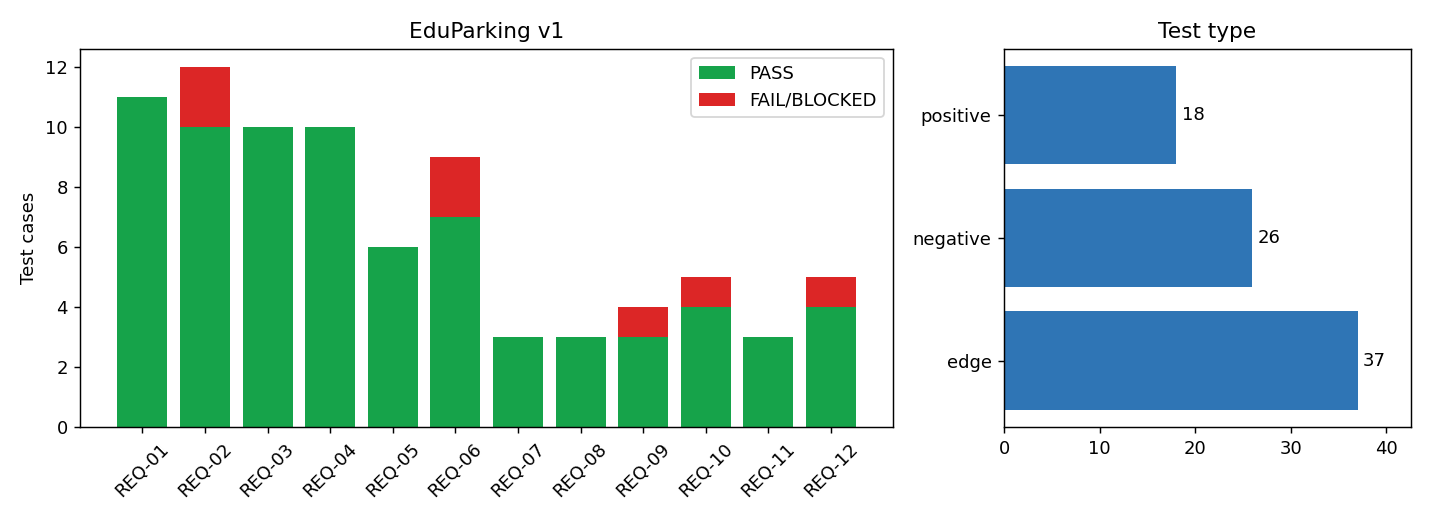

In [13]:
display(Image("reports/v1/chart.png"))

## Bước 5 — STEP 5: Xác nhận FAIL là lỗi ứng dụng (E09)
Mỗi FAIL được đối chiếu với requirement để chắc chắn lỗi nằm ở ứng dụng, không phải ở test (xem Defect Report trong báo cáo).

In [14]:
fails = results[results.status != "PASS"][["test_id", "requirement", "type", "test_name", "message"]]
display(fails.style.hide(axis="index"))

test_id,requirement,type,test_name,message
TC-019,REQ-02,edge,test_edge_minutes_around_full_hours[60-1],"assert 2 == 1 + where 2 = parked_hours(datetime.datetime(2026, 3, 1, 8, 0), (datetime.datetime(2026, 3, 1, 8, 0) + datetime.timedelta(seconds=3600))) + wh"
TC-021,REQ-02,edge,test_edge_minutes_around_full_hours[120-2],"assert 3 == 2 + where 3 = parked_hours(datetime.datetime(2026, 3, 1, 8, 0), (datetime.datetime(2026, 3, 1, 8, 0) + datetime.timedelta(seconds=7200))) + wh"
TC-055,REQ-06,edge,test_edge_debt_around_100000[100000-False],AssertionError: assert True is False + where True = can_enter('59A-12345') + where can_enter = .can_enter
TC-058,REQ-06,edge,test_edge_check_in_with_debt_exactly_100000_raises_not_allowed,Failed: DID NOT RAISE
TC-066,REQ-09,negative,test_negative_rejected_check_in_keeps_occupied,assert 2 == 1 + where 2 = .occupied + where = <test_par
TC-072,REQ-10,edge,test_edge_exactly_four_hours_motorbike_costs_5000,"AssertionError: assert 7000 == 5000 + where 7000 = check_out('59A-00001', (datetime.datetime(2026, 3, 1, 8, 0) + datetime.timedelta(seconds=14400))) + whe"
TC-078,REQ-12,positive,test_positive_lost_ticket_adds_50000_to_revenue,assert 5000 == 55000 + where 5000 = .revenue + where =


In [15]:
# Tái hiện nhanh từng lỗi bằng tay (chỉ để quan sát, v1 chưa sửa)
from datetime import datetime, timedelta
from parking_app import ParkingLot, parked_hours
T0 = datetime(2026, 3, 1, 8, 0)

print("DEF-01 parked_hours đúng 60 phút:", parked_hours(T0, T0 + timedelta(minutes=60)), "(expected 1)")
lot = ParkingLot(2); lot.debts["59A-12345"] = 100_000
print("DEF-02 can_enter nợ đúng 100.000:", lot.can_enter("59A-12345"), "(expected False)")
lot = ParkingLot(2); lot.check_in("59A-00001", "CAR", T0)
try: lot.check_in("59A-00001", "CAR", T0)
except ValueError as e: print("DEF-03", e, "| occupied =", lot.occupied, "(expected 1)")
lot = ParkingLot(2); lot.check_in("59A-00001", "MOTORBIKE", T0)
fee = lot.check_out("59A-00001", T0 + timedelta(hours=1), lost_ticket=True)
print("DEF-04 fee =", fee, "| revenue =", lot.revenue, "(expected 55000 / 55000)")

DEF-01 parked_hours đúng 60 phút: 2 (expected 1)
DEF-02 can_enter nợ đúng 100.000: True (expected False)
DEF-03 ALREADY_INSIDE | occupied = 2 (expected 1)
DEF-04 fee = 55000 | revenue = 5000 (expected 55000 / 55000)


## Bước 6 — STEP 6: Sửa lỗi (v2) và regression (E10)

In [16]:
from pathlib import Path

source = Path("parking_app.py").read_text(encoding="utf-8")
Path("parking_app_v1.py").write_text(source, encoding="utf-8")      # giữ bản cũ làm bằng chứng
fixes = [
    # DEF-01 (REQ-02): làm tròn lên theo giờ, đúng 60 phút = 1 giờ (thêm import math + sửa parked_hours)
    # DEF-02 (REQ-06): nợ phải DƯỚI 100.000 (<=  ->  <)
    # DEF-03 (REQ-09): chỉ tăng occupied SAU khi đã kiểm tra ALREADY_INSIDE
    # DEF-04 (REQ-12): cộng phụ thu TRƯỚC khi ghi doanh thu
    ("import re\n", "import math\nimport re\n"),
    ("""    minutes = int((time_out - time_in).total_seconds() // 60)
    return minutes // 60 + 1
""", """    seconds = (time_out - time_in).total_seconds()
    return max(1, math.ceil(seconds / 3600))
"""),
    ("self.debts.get(plate, 0) <= DEBT_LIMIT", "self.debts.get(plate, 0) < DEBT_LIMIT"),
    ("""        self.occupied += 1
        if plate in self.inside:
            raise ValueError("ALREADY_INSIDE")
""", """        if plate in self.inside:
            raise ValueError("ALREADY_INSIDE")
        self.occupied += 1
"""),
    ("""        self.revenue += fee
        if lost_ticket:
            fee += LOST_TICKET
""", """        if lost_ticket:
            fee += LOST_TICKET
        self.revenue += fee
"""),
]
for old, new in fixes:
    assert source.count(old) == 1, old
    source = source.replace(old, new)
Path("parking_app.py").write_text(source, encoding="utf-8")
print("Đã áp dụng", len(fixes), "bản sửa")

Đã áp dụng 5 bản sửa


In [17]:
results2, summary2, trace2 = build_report("EduParking v2", "parking_app", TESTS, REQUIREMENTS, "reports/v2")

EduParking v2: executed 81 | PASS 81 | FAIL 0 | BLOCKED 0 | line 100.0% | branch 100.0%


In [18]:
compare = pd.concat([summary.assign(version="v1"), summary2.assign(version="v2")]).set_index("version")
display(compare)
assert summary2.loc[0, "fail"] == 0 and summary2.loc[0, "blocked"] == 0, "v2 vẫn còn FAIL"
assert summary2.loc[0, "line_cov_%"] >= 95 and summary2.loc[0, "branch_cov_%"] >= 90, "coverage chưa đạt ngưỡng"

,executed,pass,fail,blocked,pass_rate_%,req_covered,line_cov_%,branch_cov_%
version,,,,,,,,
v1,81,74,7,0,91.4,12/12,100.0,100.0
v2,81,81,0,0,100.0,12/12,100.0,100.0


,requirement,PASS,FAIL,BLOCKED,result
0,REQ-01,11,0,0,PASS
1,REQ-02,12,0,0,PASS
2,REQ-03,10,0,0,PASS
3,REQ-04,10,0,0,PASS
4,REQ-05,6,0,0,PASS
5,REQ-06,9,0,0,PASS
6,REQ-07,3,0,0,PASS
7,REQ-08,3,0,0,PASS
8,REQ-09,4,0,0,PASS
9,REQ-10,5,0,0,PASS


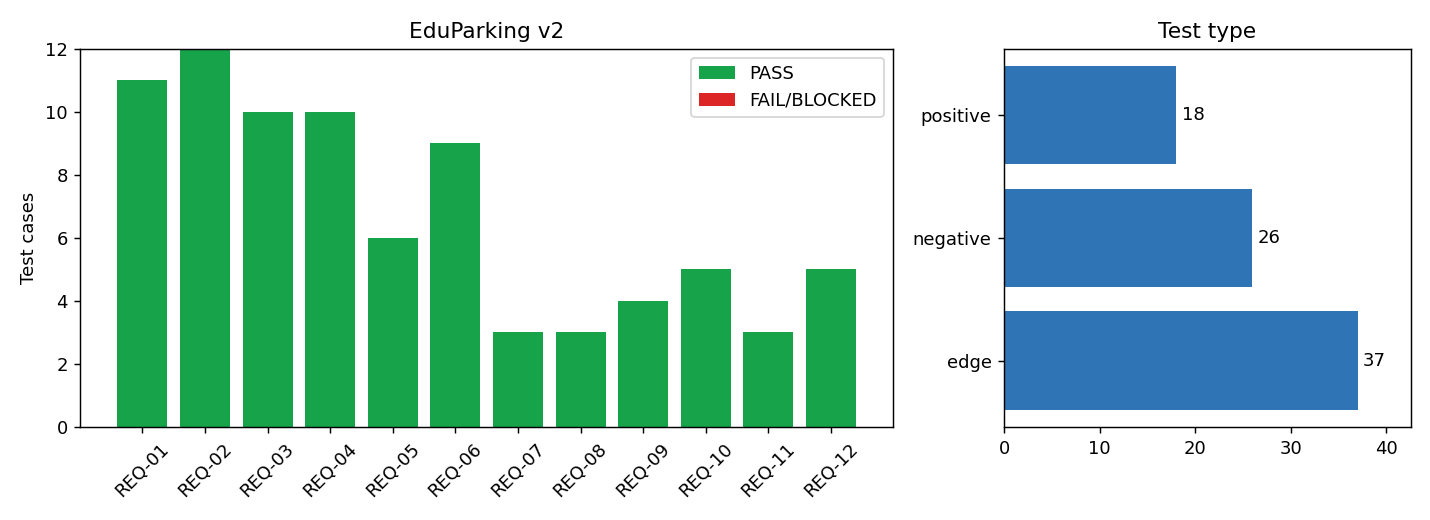

In [19]:
display(trace2[["requirement", "PASS", "FAIL", "BLOCKED", "result"]])
display(Image("reports/v2/chart.png"))

In [20]:
# Đối chiếu từng test: v1 -> v2 (regression)
diff = results[["test_id", "test_name", "status"]].merge(results2[["test_id", "status"]], on="test_id", suffixes=("_v1", "_v2"))
display(diff[diff.status_v1 != diff.status_v2].style.hide(axis="index"))
print("Số test đã chạy lại:", len(results2), "| không còn test nào đổi từ PASS sang FAIL:",
      not ((diff.status_v1 == "PASS") & (diff.status_v2 != "PASS")).any())

test_id,test_name,status_v1,status_v2
TC-019,test_edge_minutes_around_full_hours[60-1],FAIL,PASS
TC-021,test_edge_minutes_around_full_hours[120-2],FAIL,PASS
TC-055,test_edge_debt_around_100000[100000-False],FAIL,PASS
TC-058,test_edge_check_in_with_debt_exactly_100000_raises_not_allowed,FAIL,PASS
TC-066,test_negative_rejected_check_in_keeps_occupied,FAIL,PASS
TC-072,test_edge_exactly_four_hours_motorbike_costs_5000,FAIL,PASS
TC-078,test_positive_lost_ticket_adds_50000_to_revenue,FAIL,PASS


Số test đã chạy lại: 81 | không còn test nào đổi từ PASS sang FAIL: True


## Bước 7 — Chất lượng bộ test: coverage và mutant (E11)
### 7.1. Coverage 100% nhưng không kiểm tra gì (Phần 3.8)

In [21]:
%%writefile demo_coverage.py
"""Phần 3.8 / 9.1 - Coverage cao nhưng test không kiểm tra gì (chạy hết dòng nhưng không assert)."""
from datetime import datetime, timedelta

from parking_app import ParkingLot, occupancy_rate, parked_hours, parking_fee

IN = datetime(2026, 3, 1, 8, 0)


def test_runs_everything_but_checks_nothing():
    parking_fee("MOTORBIKE", 1)
    parking_fee("MOTORBIKE", 30)
    parking_fee("CAR", 30)
    for bad in (lambda: parking_fee("TRUCK", 1), lambda: parking_fee("CAR", 0),
                lambda: occupancy_rate(1, 0), lambda: parked_hours(IN, IN - timedelta(hours=1))):
        try:
            bad()
        except ValueError:
            pass
    occupancy_rate(1, 3)
    lot = ParkingLot(1)
    lot.blacklist.add("59A-99999")
    lot.debts["59A-88888"] = 200_000
    for plate, kind in (("59A-99999", "CAR"), ("59A-88888", "CAR"), ("59A-00001", "TRUCK"),
                        ("59A-00001", "CAR"), ("59A-00002", "CAR"), ("59A-00001", "CAR")):
        try:
            lot.check_in(plate, kind, IN)
        except ValueError:
            pass
    for plate in ("59A-00001", "59A-00009"):
        try:
            lot.check_out(plate, IN + timedelta(hours=3), lost_ticket=True)
        except ValueError:
            pass

Writing demo_coverage.py


In [22]:
!{sys.executable} -m pytest -p no:cacheprovider -q --cov=parking_app --cov-branch --cov-report=term-missing demo_coverage.py

.                                                                        [100%]
================================ tests coverage ================================
_______________ coverage: platform linux, python 3.13.18-final-0 _______________

Name             Stmts   Miss Branch BrPart  Cover   Missing
------------------------------------------------------------
parking_app.py      57      1     20      2    96%   63, 72->74
------------------------------------------------------------
TOTAL               57      1     20      2    96%
1 passed in 0.03s


### 7.2. Mutant trên v2: cố ý làm hỏng code, bộ test có phát hiện không?

In [23]:
import shutil, subprocess, tempfile
import pandas as pd
mutants = [
 ("M1: bỏ mức trần (return fee)", "return min(fee, cap)", "return fee"),
 ("M2: hours < 1 thành hours < 0", "if hours < 1:", "if hours < 0:"),
 ("M3: nợ DƯỚI 100.000 thành <=", "self.debts.get(plate, 0) < DEBT_LIMIT", "self.debts.get(plate, 0) <= DEBT_LIMIT"),
 ("M4: bãi đầy muộn 1 xe (>= thành >)", "self.occupied >= self.capacity", "self.occupied > self.capacity"),
 ("M5: phụ thu mất vé 50.000 thành 5.000", "LOST_TICKET = 50_000", "LOST_TICKET = 5_000"),
 ("M6: doanh thu ghi đè thay vì cộng dồn", "self.revenue += fee", "self.revenue = fee"),
 ("M7: tỉ lệ nhân 10 thay vì 100", "/ capacity * 100", "/ capacity * 10"),
 ("M8: gói đầu MOTORBIKE 3 giờ thay vì 4", "(5_000, 4, 2_000, 30_000)", "(5_000, 3, 2_000, 30_000)"),
 ("M9: giờ ra bằng giờ vào báo lỗi (< thành <=)", "if time_out < time_in:", "if time_out <= time_in:"),
 ("M10: hours < 1 thành hours <= 0 (tương đương)", "if hours < 1:", "if hours <= 0:"),
]
src = Path("parking_app.py").read_text(encoding="utf-8")
rows = []
for name, old, new in mutants:
    assert src.count(old) == 1, old
    with tempfile.TemporaryDirectory() as t:
        Path(t, "parking_app.py").write_text(src.replace(old, new), encoding="utf-8")
        for f in ("test_functions.py", "test_parking_lot.py"): shutil.copy(f, t)
        r = subprocess.run([sys.executable, "-m", "pytest", "-q"], cwd=t, capture_output=True, text=True)
    rows.append({"mutant": name, "killed": r.returncode == 1, "result": r.stdout.strip().splitlines()[-1]})
mutant_table = pd.DataFrame(rows)
mutant_table.to_csv("reports/v2/mutants.csv", index=False, encoding="utf-8-sig")
display(mutant_table)
print("Mutation score (không tính mutant tương đương):", f"{mutant_table.killed.sum()}/{len(mutant_table) - 1}")

,mutant,killed,result
0,M1: bỏ mức trần (return fee),True,"5 failed, 76 passed in 0.18s"
1,M2: hours < 1 thành hours < 0,True,"1 failed, 80 passed in 0.13s"
2,M3: nợ DƯỚI 100.000 thành <=,True,"2 failed, 79 passed in 0.14s"
3,M4: bãi đầy muộn 1 xe (>= thành >),True,"4 failed, 77 passed in 0.40s"
4,M5: phụ thu mất vé 50.000 thành 5.000,True,"3 failed, 78 passed in 0.14s"
5,M6: doanh thu ghi đè thay vì cộng dồn,True,"1 failed, 80 passed in 0.12s"
6,M7: tỉ lệ nhân 10 thay vì 100,True,"3 failed, 78 passed in 0.19s"
7,M8: gói đầu MOTORBIKE 3 giờ thay vì 4,True,"6 failed, 75 passed in 0.15s"
8,M9: giờ ra bằng giờ vào báo lỗi (< thành <=),True,"1 failed, 80 passed in 0.13s"
9,M10: hours < 1 thành hours <= 0 (tương đương),False,81 passed in 0.10s


Mutation score (không tính mutant tương đương): 9/9


In [34]:
# Mutant M1 (bỏ mức trần) có bị bộ test yếu của demo_coverage.py phát hiện không?
with tempfile.TemporaryDirectory() as tmp:
    src = Path("parking_app.py").read_text(encoding="utf-8").replace("return min(fee, cap)", "return fee")
    Path(tmp, "parking_app.py").write_text(src, encoding="utf-8")
    shutil.copy("demo_coverage.py", tmp)
    r = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider",  "demo_coverage.py"], cwd=tmp, capture_output=True, text=True)
print("Bộ test yếu (coverage cao) :", r.stdout.strip().splitlines()[-1], "-> mutant SỐNG" if r.returncode == 0 else "-> bị giết")

Bộ test yếu (coverage cao) : 1 passed in 0.01s -> mutant SỐNG


## Bước 8 — Phần 3.3 và Phần 4.1: minh chứng chạy thật

In [25]:
%%writefile test_problem_solving.py
"""Minh chứng cho Phần 3.3: check-out với giờ ra sai (giờ ra < giờ vào) phải KHÔNG đổi state."""
from datetime import datetime, timedelta

import pytest

from parking_app import ParkingLot

IN = datetime(2026, 3, 1, 8, 0)
A = "59A-00001"


class TestPS33InvalidCheckOutTime:
    def setup_method(self):
        self.lot = ParkingLot(2)
        self.lot.check_in(A, "MOTORBIKE", IN)

    def test_negative_clock_skew_raises_invalid_time(self):
        with pytest.raises(ValueError, match="INVALID_TIME"):
            self.lot.check_out(A, IN - timedelta(minutes=5))

    def test_negative_clock_skew_keeps_vehicle_occupied_and_revenue(self):
        with pytest.raises(ValueError):
            self.lot.check_out(A, IN - timedelta(minutes=5))
        assert A in self.lot.inside
        assert self.lot.occupied == 1
        assert self.lot.revenue == 0

    def test_positive_retry_with_correct_time_succeeds(self):
        with pytest.raises(ValueError):
            self.lot.check_out(A, IN - timedelta(minutes=5))
        assert self.lot.check_out(A, IN + timedelta(hours=1)) == 5_000
        assert self.lot.occupied == 0
        assert self.lot.revenue == 5_000

Writing test_problem_solving.py


In [26]:
!{sys.executable} -m pytest -p no:cacheprovider -q test_problem_solving.py

...                                                                      [100%]
3 passed in 0.02s


In [27]:
%%writefile demo_interview.py
"""Phần 4.1 - Code Interview A, B, C, D. File này chạy riêng, KHÔNG nằm trong Test Report.
Các test có chữ 'bad' là bản SAI (để thấy vì sao sai); chữ 'fixed' là bản đã sửa."""
from datetime import datetime

import pytest

from parking_app import ParkingLot, parking_fee

IN = datetime(2026, 3, 1, 8, 0)


# ---------- A: test không bao giờ đỏ ----------
def fake_parking_fee(vehicle, hours):
    return 0                                   # hàm sai: KHÔNG ném lỗi với xe lạ


def test_A_bad_always_green():
    try:
        fake_parking_fee("TRUCK", 1)
    except ValueError:
        assert True                            # chỉ chạy khi có lỗi; không có lỗi -> không assert nào -> PASS


def test_A_fixed_detects_missing_exception():  # trên hàm sai này test PHẢI ĐỎ (FAIL là đúng ý đồ)
    with pytest.raises(ValueError, match="INVALID_VEHICLE"):
        fake_parking_fee("TRUCK", 1)


def test_A_fixed_on_real_function():
    with pytest.raises(ValueError, match="INVALID_VEHICLE"):
        parking_fee("TRUCK", 1)


# ---------- B: hai lệnh trong pytest.raises ----------
def test_B_bad_same_plate():
    lot = ParkingLot(2)
    with pytest.raises(ValueError):
        lot.check_in("59A-1111", "CAR", IN)    # biển số 4 chữ số -> NOT_ALLOWED, ném lỗi ngay ở dòng này
        lot.check_in("59A-1111", "CAR", IN)    # dòng này KHÔNG BAO GIỜ chạy


def test_B_fixed_same_plate():
    lot = ParkingLot(2)
    lot.check_in("59A-11111", "CAR", IN)       # Arrange: biển số hợp lệ, vào lần 1 (nằm NGOÀI raises)
    with pytest.raises(ValueError, match="ALREADY_INSIDE"):
        lot.check_in("59A-11111", "CAR", IN)   # Act: đúng một lệnh trong raises
    assert lot.occupied == 1                   # Assert state


# ---------- C: expected chép lại code ----------
def test_C_bad_fee():
    hours = 6
    expected = 5_000 + max(0, hours - 4) * 2_000     # chép công thức của code -> sai công thức cũng PASS
    assert parking_fee("MOTORBIKE", hours) == expected


def test_C_fixed_fee():
    assert parking_fee("MOTORBIKE", 6) == 9_000       # tính tay: 5.000 + 2 giờ x 2.000


# ---------- D: dùng chung dữ liệu ----------
class TestLotSharedBad:
    lot = ParkingLot(1)                                # biến cấp lớp, dùng chung giữa các test

    def test_positive_check_in(self):
        self.lot.check_in("59A-11111", "CAR", IN)
        assert self.lot.occupied == 1

    def test_positive_lot_starts_empty(self):          # chạy SAU test trên -> occupied = 1 -> FAIL
        assert self.lot.occupied == 0


class TestLotFixed:
    def setup_method(self):
        self.lot = ParkingLot(1)                       # mỗi test một bãi mới

    def test_positive_check_in(self):
        self.lot.check_in("59A-11111", "CAR", IN)
        assert self.lot.occupied == 1

    def test_positive_lot_starts_empty(self):
        assert self.lot.occupied == 0

Writing demo_interview.py


Hai test FAIL dưới đây là **đúng ý đồ**: `test_A_fixed_detects_missing_exception` (hàm giả không ném lỗi nên test đã sửa phải đỏ) và `TestLotSharedBad::test_positive_lot_starts_empty` (dùng chung state làm test phụ thuộc thứ tự).

In [28]:
!{sys.executable} -m pytest -p no:cacheprovider -q --tb=line demo_interview.py

.F......F..                                                              [100%]
=================================== FAILURES ===================================
/content/stlab03_work/demo_interview.py:25: Failed: DID NOT RAISE <class 'ValueError'>
/content/stlab03_work/demo_interview.py:70: assert 1 == 0
=========================== short test summary info ============================
FAILED demo_interview.py::test_A_fixed_detects_missing_exception - Failed: DID NOT RAISE <class 'ValueError'>
FAILED demo_interview.py::TestLotSharedBad::test_positive_lot_starts_empty - assert 1 == 0
2 failed, 9 passed in 0.02s


In [29]:
!{sys.executable} -m pytest -p no:cacheprovider -q demo_interview.py::TestLotSharedBad::test_positive_lot_starts_empty

.                                                                        [100%]
1 passed in 0.01s


In [30]:
# Phần 3.4: bản đã sửa (TestLotFixed) xanh ở mọi thứ tự - chạy theo thứ tự ĐẢO
!{sys.executable} -m pytest -p no:cacheprovider -q demo_interview.py::TestLotFixed::test_positive_lot_starts_empty demo_interview.py::TestLotFixed::test_positive_check_in

..                                                                       [100%]
2 passed in 0.02s


## Bước 9 — Đóng gói report

In [31]:
for f in sorted(Path("reports").rglob("*")):
    if f.is_file():
        print(f"{f.as_posix():40s} {f.stat().st_size:>8,} bytes")

reports/v1/chart.png                       37,469 bytes
reports/v1/coverage.json                    8,491 bytes
reports/v1/dashboard.html                  30,070 bytes
reports/v1/junit.xml                       14,175 bytes
reports/v1/pytest_log.txt                   1,910 bytes
reports/v1/pytest_report.html              92,624 bytes
reports/v1/test_execution.csv               7,358 bytes
reports/v1/test_report.xlsx                12,581 bytes
reports/v2/chart.png                       37,529 bytes
reports/v2/coverage.json                    8,500 bytes
reports/v2/dashboard.html                  27,998 bytes
reports/v2/junit.xml                       10,278 bytes
reports/v2/mutants.csv                        794 bytes
reports/v2/pytest_log.txt                     564 bytes
reports/v2/pytest_report.html              90,780 bytes
reports/v2/test_execution.csv               6,350 bytes
reports/v2/test_report.xlsx                11,382 bytes


In [33]:
import shutil
print(shutil.make_archive("STLab03_reports", "zip", "reports").split(os.sep)[-1])
# Trên Colab: bỏ dấu # ở hai dòng dưới để tải về máy
from google.colab import files
files.download("STLab03_reports.zip")

STLab03_reports.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>